In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

In [2]:
import multiprocessing as mp
import time
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Pretty, display
from scipy.optimize import differential_evolution, minimize

import geodesiq as gq

In [3]:
# Model and worker code live in three_level.py so spawned worker processes can import them
import three_level as tls
from three_level import build_model

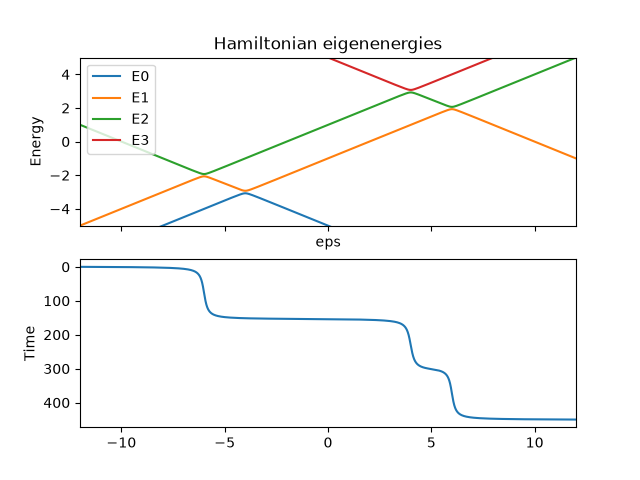

In [4]:
# ----- Set system and control parameters -----
alpha, beta = 2, 2
dia_alpha, dia_beta = -5, 5

DeltaL = 1
phiL = 0.1
phiR = np.pi / 2

# tc = 0.8 * DeltaL
# DeltaR = 2 * DeltaL

tc = 0.1 * DeltaL
DeltaR = 5 * DeltaL

tee = tc / 2 * (1 + np.exp(1j * (phiL - phiR)))
teg = tc / 2 * (np.exp(1j * phiL) - np.exp(1j * phiR))

eps0, epsf = -12 * DeltaL, 12 * DeltaL
MODEL_PARAMS = dict(
    DeltaL=DeltaL,
    DeltaR=DeltaR,
    tee=tee,
    teg=teg,
    eps0=eps0,
    epsf=epsf,
    alpha=alpha,
    beta=beta,
    dia_alpha=dia_alpha,
    dia_beta=dia_beta,
)
model = build_model(**MODEL_PARAMS)

fig, axs = plt.subplots(2, sharex=True)
model.plot_eigenvalues(ax=axs[0])
axs[0].set_ylim(-5, 5)
axs[0].set_xlim(-12, 12)

model.set_control(alpha=alpha, beta=beta, dia_alpha=dia_alpha, dia_beta=dia_beta)
pulse = model.synthesize_pulse(450)
axs[1].plot(pulse.pulse, pulse.times)
axs[1].set_ylim(*axs[1].get_ylim()[::-1])
axs[1].set_ylabel("Time");


interactive(children=(FloatSlider(value=2.0, description='alpha', max=5.0, min=-5.0), FloatSlider(value=2.0, d…

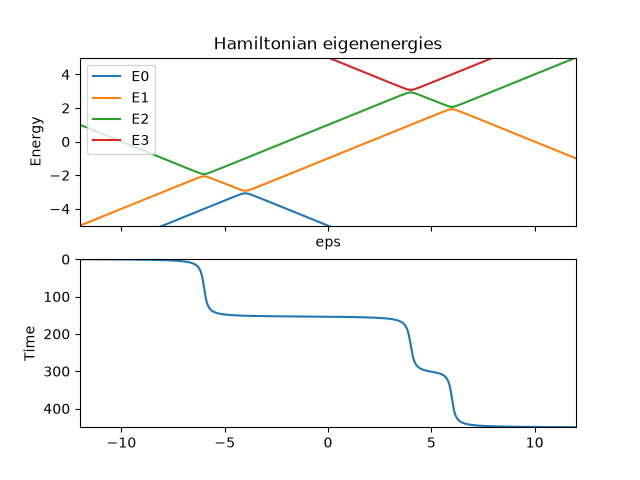

In [5]:
import ipywidgets as widgets

# ----- Interactive exploration of the exponents -----
# Separate model so the sliders do not modify `model` used in the cells below
slider_model = build_model(**MODEL_PARAMS)
slider_duration = 450

fig_s, axs_s = plt.subplots(2, sharex=True)
slider_model.plot_eigenvalues(ax=axs_s[0])
axs_s[0].set_ylim(-5, 5)
axs_s[0].set_xlim(-12, 12)

(pulse_line,) = axs_s[1].plot([], [])
axs_s[1].set_ylim(slider_duration, 0)
axs_s[1].set_ylabel("Time")


def update_pulse(alpha, beta, dia_alpha, dia_beta):
    try:
        slider_model.set_control(alpha=alpha, beta=beta, dia_alpha=dia_alpha, dia_beta=dia_beta)
        pulse = slider_model.synthesize_pulse(slider_duration)
        pulse_line.set_data(pulse.pulse, pulse.times)
        axs_s[1].set_title("")
    except Exception as e:
        pulse_line.set_data([], [])
        axs_s[1].set_title(f"Failed: {e}", fontsize=8)
    fig_s.canvas.draw_idle()


slider_kw = dict(min=-5, max=5, step=0.1)
widgets.interact(
    update_pulse,
    alpha=widgets.FloatSlider(value=alpha, description="alpha", **slider_kw),
    beta=widgets.FloatSlider(value=beta, description="beta", **slider_kw),
    dia_alpha=widgets.FloatSlider(value=dia_alpha, description="dia_alpha", **slider_kw),
    dia_beta=widgets.FloatSlider(value=dia_beta, description="dia_beta", **slider_kw),
);

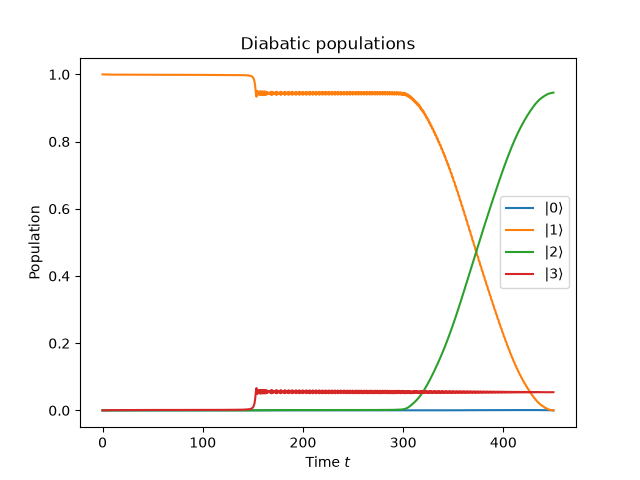

In [6]:
dynamics = gq.Dynamics(model, 450)

dynamics.plot_populations(basis="diabatic");


In [7]:
tls.silence_warnings()  # main process (polish phase)

In [ ]:
# ---------------------------------------------------------------- EDIT ---
DURATION = 400  # fixed total time, not optimised
PARAM_NAMES = ["alpha", "beta", "alpha_dia", "beta_dia"]
BOUNDS = [
    (-5, 5),  # alpha
    (-5, 5),  # beta
    (-5, 5),  # alpha_dia
    (-5, 5),  # beta_dia
]


# -------------------------------------------------------------------------


class Tracer:
    """Live progress block, updated in place. Shows current status + last few improvements."""

    def __init__(self, label, print_every=1, history=5):
        self.label, self.print_every = label, print_every
        self.t0, self.it = time.perf_counter(), 0
        self.best_fun, self.best_x = np.inf, None
        self.improvements = deque(maxlen=history)
        self.handle = None

    def _fmt_params(self, x):
        return "  ".join(f"{n}={v:.6g}" for n, v in zip(PARAM_NAMES, x, strict=False))

    def __call__(self, intermediate_result):  # name must be exactly this
        self.it += 1
        r = intermediate_result
        elapsed = time.perf_counter() - self.t0

        improved = r.fun < self.best_fun
        if improved:
            self.best_fun, self.best_x = float(r.fun), np.array(r.x, copy=True)
            self.improvements.append(f"  it {self.it:4d}  t={elapsed:7.1f}s  1-F={r.fun:.3e}")

        if not (improved or self.it % self.print_every == 0):
            return

        conv = getattr(r, "convergence", None)
        conv_s = f"   conv={conv:.2e}" if conv is not None else ""
        text = (
            f"[{self.label}]  iteration {self.it}   elapsed {elapsed:.1f}s{conv_s}\n"
            f"best F   = {1 - self.best_fun:.10f}   (1-F = {self.best_fun:.3e})\n"
            f"best x   : {self._fmt_params(self.best_x)}\n"
            f"recent improvements:\n" + "\n".join(self.improvements)
        )

        if self.handle is None:
            self.handle = display(Pretty(text), display_id=True)
        else:
            self.handle.update(Pretty(text))


def print_result(title, x, fun):
    print(f"\n=== {title} ===\nFidelity   = {1 - fun:.12f}\nInfidelity = {fun:.3e}")
    print(f"  {'duration':10s} = {DURATION:.10g}  (fixed)")
    for n, v in zip(PARAM_NAMES, x, strict=False):
        print(f"  {n:10s} = {v:.10g}")


# ------------------------------------------------------- global search ---
n_workers = mp.cpu_count()
print(f"Using {n_workers} worker processes")
de_tracer = Tracer("DE", print_every=5)
# "spawn" is the only start method on Windows: workers import `three_level`
# and rebuild the model from MODEL_PARAMS in their initializer.
ctx = mp.get_context("spawn")

try:
    with ctx.Pool(n_workers, initializer=tls.init_worker, initargs=(MODEL_PARAMS, DURATION)) as pool:
        res = differential_evolution(
            tls.objective,
            BOUNDS,
            strategy="best1bin",
            popsize=16,
            maxiter=600,
            tol=1e-10,
            atol=0.0,
            mutation=(0.5, 1.0),
            recombination=0.7,
            init="latinhypercube",
            polish=False,
            updating="deferred",
            workers=pool.map,
            callback=de_tracer,
            seed=0,
        )
    print_result(f"DE ({res.nfev} evals, {res.message})", res.x, res.fun)
    x_best, f_best = res.x, res.fun
except KeyboardInterrupt:
    print("\nInterrupted, keeping best point so far.")
    x_best, f_best = de_tracer.best_x, de_tracer.best_fun

# -------------------------------------------------------- local polish ---
tls.configure(MODEL_PARAMS, DURATION)  # model for `tls.objective` in the main process
polish_tracer = Tracer("polish", print_every=20)
try:
    loc = minimize(
        tls.objective,
        x_best,
        method="Nelder-Mead",
        bounds=BOUNDS,
        callback=polish_tracer,
        options={"xatol": 1e-10, "fatol": 1e-13, "maxiter": 3000, "adaptive": True},
    )
    if loc.fun < f_best:
        x_best, f_best = loc.x, loc.fun
except KeyboardInterrupt:
    print("\nPolish interrupted.")
    if polish_tracer.best_fun < f_best:
        x_best, f_best = polish_tracer.best_x, polish_tracer.best_fun

print_result("FINAL", x_best, f_best)

Using 24 worker processes


[DE]  iteration 600   elapsed 345.1s   conv=1.40e-05
best F   = 0.9962858324   (1-F = 3.714e-03)
best x   : alpha=4.89533  beta=3.45295  alpha_dia=-3.92048  beta_dia=4.99999
recent improvements:
  it  389  t=  225.2s  1-F=3.714e-03
  it  398  t=  230.5s  1-F=3.714e-03
  it  402  t=  232.6s  1-F=3.714e-03
  it  405  t=  234.3s  1-F=3.714e-03
  it  421  t=  243.5s  1-F=3.714e-03


=== DE (38464 evals, Maximum number of iterations has been exceeded.) ===
Fidelity   = 0.996285832384
Infidelity = 3.714e-03
  duration   = 400  (fixed)
  alpha      = 4.895327701
  beta       = 3.452946901
  alpha_dia  = -3.92047795
  beta_dia   = 4.999991731


[polish]  iteration 1920   elapsed 871.8s
best F   = 0.9962858324   (1-F = 3.714e-03)
best x   : alpha=4.89533  beta=3.45295  alpha_dia=-3.92048  beta_dia=4.99999
recent improvements:
  it    1  t=    0.8s  1-F=3.714e-03


Polish interrupted.

=== FINAL ===
Fidelity   = 0.996285832384
Infidelity = 3.714e-03
  duration   = 400  (fixed)
  alpha      = 4.895327701
  beta       = 3.452946901
  alpha_dia  = -3.92047795
  beta_dia   = 4.999991731


Text(0, 0.5, 'Time')

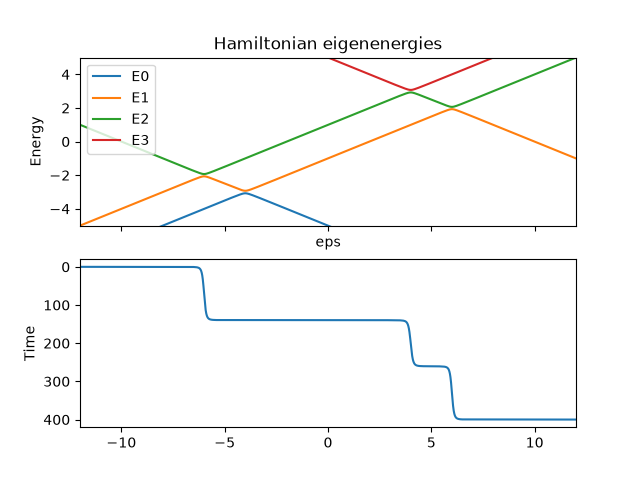

In [12]:
fig, axs = plt.subplots(2, sharex=True)
model.plot_eigenvalues(ax=axs[0])
axs[0].set_ylim(-5, 5)
axs[0].set_xlim(-12, 12)

model.set_control(alpha=x_best[0], beta=x_best[1], dia_alpha=x_best[2], dia_beta=x_best[3])
pulse = model.synthesize_pulse(DURATION)
axs[1].plot(pulse.pulse, pulse.times)
axs[1].set_ylim(*axs[1].get_ylim()[::-1])
axs[1].set_ylabel("Time")